In [8]:
!pip install -q kagglehub

import kagglehub
path = kagglehub.dataset_download("salmansajid05/oral-diseases")
print("Path:", path)

Path: /root/.cache/kagglehub/datasets/salmansajid05/oral-diseases/versions/3


In [9]:
import os
for root, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith(('.jpg','.jpeg','.png'))]
    if imgs:
        print(root.replace(path,''), '->', len(imgs))

/Gingivitis/Gingivitis -> 2349
/hypodontia/hypodontia -> 1251
/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images/train -> 1493
/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images/val -> 49
/Data caries/Data caries/caries orignal data set/done -> 219
/Data caries/Data caries/caries augmented data set/preview -> 2382
/Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset -> 265
/Mouth Ulcer/Mouth Ulcer/Mouth_Ulcer_augmented_DataSet/preview -> 2541
/Calculus/Calculus -> 1296
/Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset -> 183
/Tooth Discoloration/Tooth Discoloration /Tooth_discoloration_augmented_dataser/preview -> 1834


In [10]:
import os, glob, random, numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import matplotlib.pyplot as plt, seaborn as sns

random.seed(42); np.random.seed(42); torch.manual_seed(42)
dev = "cuda" if torch.cuda.is_available() else "cpu"

USE_AUGMENTED = True   # False = الصور الأصلية بس (أنضف، لكن أقل عدداً)

KEYS = [("calculus","Calculus"),("hypodontia","Hypodontia"),("gingivitis","Gingivitis"),
        ("caries","Caries"),("ulcer","Ulcer"),("discolor","Discoloration")]

rows = []
for p in glob.glob(path + "/**/*", recursive=True):
    if not p.lower().endswith((".jpg",".jpeg",".png")): continue
    low = p.lower()
    if "yolo" in low: continue
    is_orig = ("original" in low) or ("orignal" in low)
    is_aug  = ("augment" in low)
    if not USE_AUGMENTED and is_aug: continue
    if USE_AUGMENTED and is_orig: continue   # نتجنب تكرار الأصل مع نسخه
    for k, name in KEYS:
        if k in low:
            rows.append((p, name)); break

df = pd.DataFrame(rows, columns=["path","label"])
classes = sorted(df.label.unique()); c2i = {c:i for i,c in enumerate(classes)}
df["y"] = df.label.map(c2i)
print(df.label.value_counts()); print(classes)

label
Ulcer            2541
Caries           2382
Gingivitis       2349
Discoloration    1834
Calculus         1296
Hypodontia       1251
Name: count, dtype: int64
['Calculus', 'Caries', 'Discoloration', 'Gingivitis', 'Hypodontia', 'Ulcer']


In [11]:
tr, tmp = train_test_split(df, test_size=0.2, stratify=df.y, random_state=42)
va, te  = train_test_split(tmp, test_size=0.5, stratify=tmp.y, random_state=42)

norm = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
t_train = transforms.Compose([transforms.Resize((224,224)), transforms.RandomHorizontalFlip(),
                              transforms.RandomRotation(15), transforms.ColorJitter(0.2,0.2),
                              transforms.ToTensor(), norm])
t_eval  = transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, d, t): s.d, s.t = d.reset_index(drop=True), t
    def __len__(s): return len(s.d)
    def __getitem__(s, i):
        r = s.d.iloc[i]
        return s.t(Image.open(r.path).convert("RGB")), r.y

mk = lambda d,t,sh: DataLoader(DS(d,t), batch_size=32, shuffle=sh, num_workers=2, pin_memory=True)
dl_tr, dl_va, dl_te = mk(tr,t_train,True), mk(va,t_eval,False), mk(te,t_eval,False)

In [12]:
print(torch.cuda.is_available())

False


In [13]:
# 1) صور أصغر (أسرع حوالي 2x)
t_train = transforms.Compose([transforms.Resize((160,160)), transforms.RandomHorizontalFlip(),
                              transforms.ToTensor(), norm])
t_eval  = transforms.Compose([transforms.Resize((160,160)), transforms.ToTensor(), norm])

# 2) workers أكتر وbatch أكبر
mk = lambda d,t,sh: DataLoader(DS(d,t), batch_size=64, shuffle=sh, num_workers=4, pin_memory=True)
dl_tr, dl_va, dl_te = mk(tr,t_train,True), mk(va,t_eval,False), mk(te,t_eval,False)

# 3) موديل أخف: ResNet18 بدل ResNet50
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(dev)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 51.5MB/s]


In [1]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

True Tesla T4


In [13]:
path = kagglehub.dataset_download("salmansajid05/oral-diseases")

Using Colab cache for faster access to the 'oral-diseases' dataset.


Device: cuda


100%|██████████| 235M/235M [00:01<00:00, 151MB/s]

Extracting files...


Path: /root/.cache/kagglehub/datasets/salmansajid05/oral-diseases/versions/3
label
Ulcer            2541
Caries           2382
Gingivitis       2349
Discoloration    1834
Calculus         1296
Hypodontia       1251
Name: count, dtype: int64
['Calculus', 'Caries', 'Discoloration', 'Gingivitis', 'Hypodontia', 'Ulcer']
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 161MB/s]


[head] ep1 train_acc=0.678 val_acc=0.763
[head] ep2 train_acc=0.787 val_acc=0.803
[head] ep3 train_acc=0.809 val_acc=0.823
[full] ep1 train_acc=0.884 val_acc=0.922
[full] ep2 train_acc=0.930 val_acc=0.922
[full] ep3 train_acc=0.938 val_acc=0.928
[full] ep4 train_acc=0.941 val_acc=0.932
[full] ep5 train_acc=0.939 val_acc=0.933
[full] ep6 train_acc=0.942 val_acc=0.930
               precision    recall  f1-score   support

     Calculus     0.6140    0.8140    0.7000       129
       Caries     1.0000    1.0000    1.0000       239
Discoloration     1.0000    1.0000    1.0000       184
   Gingivitis     0.8724    0.7277    0.7935       235
   Hypodontia     1.0000    0.9760    0.9879       125
        Ulcer     1.0000    1.0000    1.0000       254

     accuracy                         0.9220      1166
    macro avg     0.9144    0.9196    0.9136      1166
 weighted avg     0.9316    0.9220    0.9239      1166



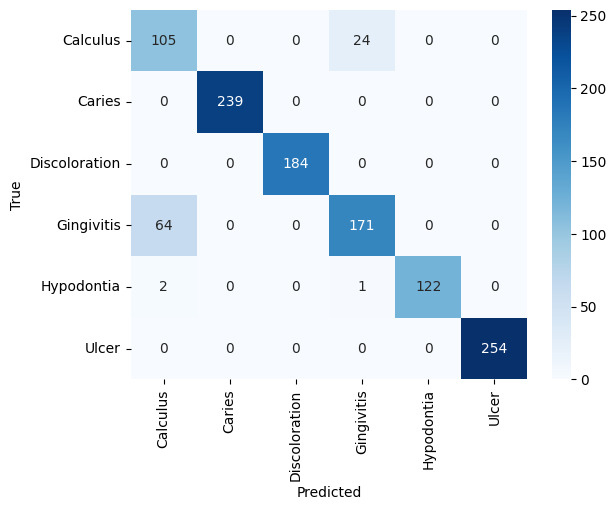

In [12]:
import os, glob, random, numpy as np, pandas as pd, torch, torch.nn as nn
import kagglehub
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import matplotlib.pyplot as plt, seaborn as sns

random.seed(42); np.random.seed(42); torch.manual_seed(42)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)
assert dev == "cuda", "الـ GPU مش شغال: Runtime > Change runtime type > T4 GPU"

# ---------- 1) تحميل الداتا ----------
path = kagglehub.dataset_download("salmansajid05/oral-diseases")
print("Path:", path)

# ---------- 2) الـ DataFrame ----------
USE_AUGMENTED = True
KEYS = [("calculus","Calculus"),("hypodontia","Hypodontia"),("gingivitis","Gingivitis"),
        ("caries","Caries"),("ulcer","Ulcer"),("discolor","Discoloration")]

rows = []
for p in glob.glob(path + "/**/*", recursive=True):
    if not p.lower().endswith((".jpg",".jpeg",".png")): continue
    low = p.lower()
    if "yolo" in low: continue
    is_orig = ("original" in low) or ("orignal" in low)
    is_aug  = ("augment" in low)
    if not USE_AUGMENTED and is_aug: continue
    if USE_AUGMENTED and is_orig: continue
    for k, name in KEYS:
        if k in low:
            rows.append((p, name)); break

df = pd.DataFrame(rows, columns=["path","label"])
classes = sorted(df.label.unique()); c2i = {c:i for i,c in enumerate(classes)}
df["y"] = df.label.map(c2i)
print(df.label.value_counts()); print(classes)

# ---------- 3) Split + DataLoaders ----------
tr, tmp = train_test_split(df, test_size=0.2, stratify=df.y, random_state=42)
va, te  = train_test_split(tmp, test_size=0.5, stratify=tmp.y, random_state=42)

norm = transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
t_train = transforms.Compose([transforms.Resize((224,224)), transforms.RandomHorizontalFlip(),
                              transforms.RandomRotation(15), transforms.ColorJitter(0.2,0.2),
                              transforms.ToTensor(), norm])
t_eval  = transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor(), norm])

class DS(Dataset):
    def __init__(s, d, t): s.d, s.t = d.reset_index(drop=True), t
    def __len__(s): return len(s.d)
    def __getitem__(s, i):
        r = s.d.iloc[i]
        return s.t(Image.open(r.path).convert("RGB")), r.y

mk = lambda d,t,sh: DataLoader(DS(d,t), batch_size=32, shuffle=sh, num_workers=2, pin_memory=True)
dl_tr, dl_va, dl_te = mk(tr,t_train,True), mk(va,t_eval,False), mk(te,t_eval,False)

# ---------- 4) الموديل والتدريب ----------
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(dev)

cnt = tr.y.value_counts().sort_index().values
w = torch.tensor(cnt.sum()/(len(cnt)*cnt), dtype=torch.float).to(dev)
crit = nn.CrossEntropyLoss(weight=w)
scaler = torch.amp.GradScaler("cuda", enabled=dev=="cuda")

def run_epoch(dl, opt=None):
    model.train(opt is not None); tot=cor=ls=0
    with torch.set_grad_enabled(opt is not None):
        for x,y in dl:
            x,y = x.to(dev), y.to(dev)
            with torch.autocast(dev, enabled=dev=="cuda"):
                out = model(x); loss = crit(out,y)
            if opt:
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            ls += loss.item()*len(y); cor += (out.argmax(1)==y).sum().item(); tot += len(y)
    return ls/tot, cor/tot

def fit(epochs, lr, tag):
    opt = torch.optim.Adam(filter(lambda p:p.requires_grad, model.parameters()), lr=lr)
    best = 0
    for e in range(epochs):
        a = run_epoch(dl_tr, opt); b = run_epoch(dl_va)
        print(f"[{tag}] ep{e+1} train_acc={a[1]:.3f} val_acc={b[1]:.3f}", flush=True)
        if b[1] > best: best = b[1]; torch.save(model.state_dict(), "best.pth")

for p in model.parameters(): p.requires_grad = False
for p in model.fc.parameters(): p.requires_grad = True
fit(3, 1e-3, "head")

for p in model.parameters(): p.requires_grad = True
fit(6, 1e-4, "full")

# ---------- 5) التقييم ----------
model.load_state_dict(torch.load("best.pth")); model.eval()
yt, yp = [], []
with torch.no_grad():
    for x,y in dl_te:
        yp += model(x.to(dev)).argmax(1).cpu().tolist(); yt += y.tolist()

print(classification_report(yt, yp, target_names=classes, digits=4))
sns.heatmap(confusion_matrix(yt,yp), annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

In [7]:
path = kagglehub.dataset_download("salmansajid05/oral-diseases")

Using Colab cache for faster access to the 'oral-diseases' dataset.


In [8]:
import kagglehub
path = kagglehub.dataset_download("salmansajid05/oral-diseases")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'oral-diseases' dataset.
Path to dataset files: /kaggle/input/oral-diseases


In [ ]:
model.load_state_dict(torch.load("best.pth")); model.eval()
yt, yp = [], []
with torch.no_grad():
    for x,y in dl_te:
        yp += model(x.to(dev)).argmax(1).cpu().tolist(); yt += y.tolist()

print(classification_report(yt, yp, target_names=classes, digits=4))
sns.heatmap(confusion_matrix(yt,yp), annot=True, fmt="d", xticklabels=classes, yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

In [15]:
from google.colab import files
files.download("best.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving 53.jpg to 53.jpg


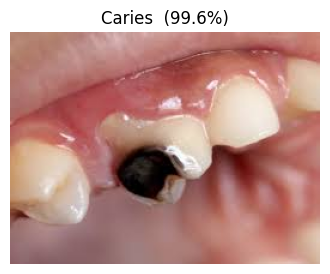

   Caries           99.6%
   Hypodontia        0.4%
   Gingivitis        0.0%


In [17]:
from google.colab import files
from IPython.display import display
import torch.nn.functional as F

# تحميل موديل الـ augmented
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model.load_state_dict(torch.load("best.pth", map_location=dev))
model = model.to(dev).eval()

# رفع الصور
up = files.upload()

for name in up.keys():
    img = Image.open(name).convert("RGB")
    x = t_eval(img).unsqueeze(0).to(dev)
    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0].cpu()
    top = probs.topk(3)
    plt.figure(figsize=(4,4)); plt.imshow(img); plt.axis("off")
    plt.title(f"{classes[top.indices[0]]}  ({top.values[0]*100:.1f}%)"); plt.show()
    for p, i in zip(top.values, top.indices):
        print(f"   {classes[i]:15s} {p*100:5.1f}%")

In [18]:
from google.colab import files
files.download("best.pth")
files.download("cm_clean.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>